<a href="https://colab.research.google.com/github/xufana/dl-knad-course/blob/main/week6/seminar_cv_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 39.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 11.2 MB/s eta 0:00:00


# Семинар: задачи компьютерного зрения

In [ ]:
import os, glob, random, time, math
import numpy as np, cv2
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device, '| torch', torch.__version__)

def seed_everything(s=0):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything(0)

device: cuda | torch 2.11.0+cu130


## Форматы разметки: Pascal VOC, YOLO, COCO


Один и тот же объект везде записан по-разному. Пример: картинка 640×480, слон с рамкой от левого верхнего угла (100, 50) до правого нижнего (300, 250).


### Pascal VOC ([сайт](http://host.robots.ox.ac.uk/pascal/VOC/), [описание формата](http://host.robots.ox.ac.uk/pascal/VOC/voc2012/devkit_doc.pdf))

```xml
<annotation>
  <filename>img001.jpg</filename>
  <size><width>640</width><height>480</height><depth>3</depth></size>
  <object>
    <name>elephant</name>
    <truncated>0</truncated>
    <difficult>0</difficult>
    <bndbox><xmin>100</xmin><ymin>50</ymin><xmax>300</xmax><ymax>250</ymax></bndbox>
  </object>
</annotation>
```

* Объектов в файле может быть сколько угодно, каждый в своём теге `<object>`.
* `truncated` — объект обрезан краем кадра, `difficult` — трудный для распознавания, такие объекты часто исключают из оценки.
* Парсится стандартным `xml.etree.ElementTree`.
* Маски для сегментации лежат отдельно: в `SegmentationClass` это PNG с номером класса в пикселе, значение 255 помечает границы объектов, их игнорируют.
* Нумерация пикселей в оригинальной разметке VOC начинается с 1, поэтому встречаются датасеты со сдвигом на единицу.

### YOLO ([детекция](https://docs.ultralytics.com/datasets/detect/), [сегментация](https://docs.ultralytics.com/datasets/segment/))

```
# img001.txt — одна строка на объект: class cx cy w h
1 0.3125 0.3125 0.3125 0.4167
```

* Структура папок: `images/train`, `images/val` и рядом `labels/train`, `labels/val` с одноимёнными `.txt`.
* Для сегментации вместо четырёх чисел идёт полигон: `class x1 y1 x2 y2 ... xn yn`, координаты тоже нормированы.
* Картинка без объектов: файла нет или он пустой.
* Имена классов лежат отдельно, в `data.yaml`, в самом `.txt` только номера.

### COCO ([формат](https://cocodataset.org/#format-data))

```json
{
  "images":      [{"id": 1, "file_name": "img001.jpg", "width": 640, "height": 480}],
  "annotations": [{"id": 10, "image_id": 1, "category_id": 22,
                   "bbox": [100, 50, 200, 200], "area": 40000, "iscrowd": 0,
                   "segmentation": [[100, 50, 300, 50, 300, 250, 100, 250]]}],
  "categories":  [{"id": 22, "name": "elephant"}]
}
```

* Всё связано по `id`: у аннотации есть `image_id` и `category_id`. Чтобы найти все рамки картинки, аннотации надо сгруппировать по `image_id`.
* `iscrowd=1` значит скопление объектов, для него `segmentation` хранится в формате RLE (сжатая маска), а не полигоном.
* Номера классов начинаются с 1, в самом COCO (80 классов) доходят до 90 с пропусками.
* Для чтения есть [pycocotools](https://github.com/cocodataset/cocoapi), она же считает mAP.

### Конвертация между форматами

* VOC → YOLO: `cx = (xmin + xmax) / 2 / W`, `cy = (ymin + ymax) / 2 / H`, `w = (xmax - xmin) / W`, `h = (ymax - ymin) / H`.
* COCO → YOLO: то же, но `xmax = x + w`. Готовый конвертер: [`convert_coco` в Ultralytics](https://docs.ultralytics.com/reference/data/converter/).


In [ ]:
!mkdir -p /content/data
!cd /content/data && wget -q https://github.com/ultralytics/assets/releases/download/v0.0.0/crack-seg.zip && unzip -q -o crack-seg.zip -d crack-seg && rm crack-seg.zip
!cd /content/data && wget -q https://github.com/ultralytics/assets/releases/download/v0.0.0/african-wildlife.zip && unzip -q -o african-wildlife.zip -d african-wildlife && rm african-wildlife.zip
!ls /content/data/crack-seg /content/data/african-wildlife

/content/data/african-wildlife:
african-wildlife.yaml  images  labels  LICENSE.txt

/content/data/crack-seg:
crack-seg.yaml	images	labels


## Данные

Оба датасета из Ultralytics в формате YOLO:

* **crack-seg** — фото дорожных и стеновых трещин, разметка полигонами. Трещина занимает около 2% пикселей, это очень несбалансированная сегментация.
* **african-wildlife** — буйвол, слон, носорог, зебра; разметка прямоугольниками.

# Блок 1. Сегментация трещин

Формат разметки — одна строка на объект:

`class x1 y1 x2 y2 ... xn yn`, все координаты нормированы на [0, 1]. Это **полигон**, а нам для обучения нужна **маска** (картинка из 0 и 1). Значит, полигоны надо превратить в маски.

In [ ]:
R = '/content/data/crack-seg'
f = sorted(glob.glob(f'{R}/labels/train/*.txt'))[0]
print(open(f).read()[:300], '...')
print({s: len(glob.glob(f'{R}/images/{s}/*.jpg')) for s in ['train', 'val', 'test']})

0 0 0.2590149182692308 0.01704840144230769 0.2660720360576923 0.049245887019230765 0.2728594711538462 0.08973430528846153 0.27816592307692306 0.11705254807692309 0.2776890817307692 0.1383970673076923 0.2753121201923077 0.16566867548076925 0.2721635673076923 0.19660846153846154 0.27496416826923076 0. ...
{'train': 3717, 'val': 200, 'test': 112}


## Задание 1.1. Полигоны → маска

Напишите `polys_to_mask(label_path, h, w)`: вернуть `np.uint8` массив `(h, w)`, где 1 — трещина, 0 — фон. Подсказка: `cv2.fillPoly(mask, [pts], 1)`, где `pts` — целочисленный массив `(n, 2)` в пикселях. Файла может не быть (нет трещин), тогда маска пустая.

In [ ]:
def polys_to_mask(label_path, h, w):
    mask = np.zeros((h, w), np.uint8)
    if not os.path.exists(label_path):
        return mask
    with open(label_path) as f:
        for line in f:
            v = line.split()
            if len(v) < 7:
                continue
            pts = np.array(v[1:], dtype=np.float32).reshape(-1, 2)
            pts = (pts * [w, h]).round().astype(np.int32)
            cv2.fillPoly(mask, [pts], 1)
    return mask

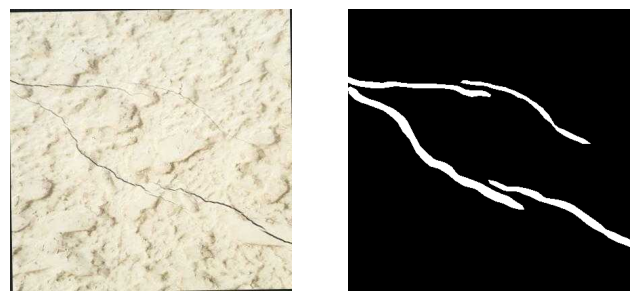

доля пикселей трещины в этом кадре: 0.0510470599112426


In [ ]:
p = sorted(glob.glob(f'{R}/images/train/*.jpg'))[0]
img = cv2.imread(p)[:, :, ::-1]
m = polys_to_mask(p.replace('images', 'labels').replace('.jpg', '.txt'), *img.shape[:2])
assert m.shape == img.shape[:2] and m.dtype == np.uint8 and set(np.unique(m)) <= {0, 1} and m.sum() > 0
fig, ax = plt.subplots(1, 2, figsize=(8, 4)); ax[0].imshow(img); ax[1].imshow(m, cmap='gray')
for a in ax: a.axis('off')
plt.show(); print('доля пикселей трещины в этом кадре:', m.mean())

## Задание 1.2. Свой Dataset

`__init__` уже написан: он читает все картинки, приводит их к `img_size × img_size` и строит маски (маски ресайзим по ближайшему соседу, иначе появятся значения между 0 и 1). Всё кэшируется в памяти, поэтому обучение не упирается в диск.

Вам нужно написать:

* `__len__`;
* `__getitem__(i)`, который возвращает пару `(x, y)`: `x` — `float32` тензор `(3, H, W)` со значениями в [0, 1], `y` — `float32` тензор `(1, H, W)` из 0 и 1;
* при `augment=True` — случайный горизонтальный и вертикальный флип и случайное изменение яркости. **Флип нужно применять к картинке и к маске одинаково**, а яркость — только к картинке.

In [ ]:
class CrackDataset(torch.utils.data.Dataset):
    def __init__(self, split, img_size=256, augment=False, root=R):
        self.augment = augment
        paths = sorted(glob.glob(f'{root}/images/{split}/*.jpg'))
        self.imgs, self.masks = [], []
        for p in paths:
            img = cv2.imread(p)[:, :, ::-1]
            m = polys_to_mask(p.replace('/images/', '/labels/').replace('.jpg', '.txt'), *img.shape[:2])
            self.imgs.append(cv2.resize(img, (img_size, img_size), interpolation=cv2.INTER_AREA))
            self.masks.append(cv2.resize(m, (img_size, img_size), interpolation=cv2.INTER_NEAREST))

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, i):
        img, m = self.imgs[i], self.masks[i]
        if self.augment:
            if random.random() < 0.5:
                img, m = img[:, ::-1], m[:, ::-1]
            if random.random() < 0.5:
                img, m = img[::-1], m[::-1]
            k = random.uniform(0.7, 1.3)
            img = np.clip(img.astype(np.float32) * k, 0, 255)
        x = torch.from_numpy(np.ascontiguousarray(img)).float().permute(2, 0, 1) / 255.
        y = torch.from_numpy(np.ascontiguousarray(m)).float().unsqueeze(0)
        return x, y

3717 200 112 | загрузка 19 c
доля трещин в train: 0.022


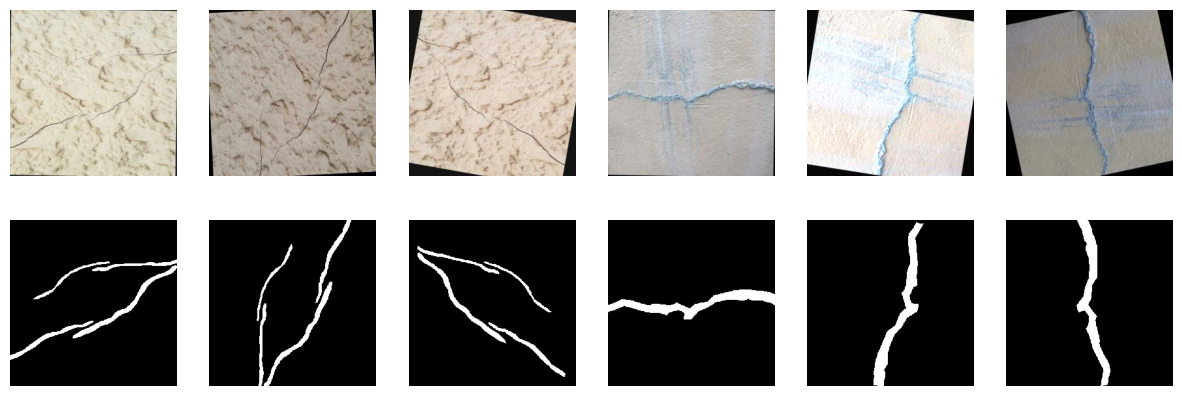

In [ ]:
t0 = time.time()
train_ds = CrackDataset('train', augment=True)
val_ds   = CrackDataset('val')
test_ds  = CrackDataset('test')
print(len(train_ds), len(val_ds), len(test_ds), f'| загрузка {time.time()-t0:.0f} c')

x, y = train_ds[0]
assert x.shape == (3, 256, 256) and y.shape == (1, 256, 256)
assert x.dtype == torch.float32 and 0 <= x.min() and x.max() <= 1
assert set(y.unique().tolist()) <= {0., 1.}
print('доля трещин в train: %.3f' % np.mean([m.mean() for m in train_ds.masks]))

fig, ax = plt.subplots(2, 6, figsize=(15, 5))
for j in range(6):
    x, y = train_ds[j]
    ax[0, j].imshow(x.permute(1, 2, 0)); ax[1, j].imshow(y[0], cmap='gray')
    ax[0, j].axis('off'); ax[1, j].axis('off')
plt.show()

## Задание 1.3. Свой DataLoader

`torch.utils.data.DataLoader` делает три вещи: перемешивает индексы, режет их на батчи и склеивает примеры в тензоры. Напишите это сами.

`MyDataLoader(dataset, batch_size, shuffle, drop_last)`:

* `__len__` — число батчей;
* `__iter__` — генератор, который отдаёт `(X, Y)`, где `X` имеет форму `(B, 3, H, W)`, `Y` — `(B, 1, H, W)`. Склеивать удобно через `torch.stack`.
* при `shuffle=True` порядок меняется при **каждом** проходе по загрузчику.

In [ ]:
class MyDataLoader:
    def __init__(self, dataset, batch_size=16, shuffle=False, drop_last=False):
        self.ds, self.bs, self.shuffle, self.drop_last = dataset, batch_size, shuffle, drop_last

    def __len__(self):
        n = len(self.ds)
        return n // self.bs if self.drop_last else math.ceil(n / self.bs)

    def __iter__(self):
        idx = torch.randperm(len(self.ds)).tolist() if self.shuffle else list(range(len(self.ds)))
        for b in range(len(self)):
            chunk = idx[b * self.bs:(b + 1) * self.bs]
            xs, ys = zip(*[self.ds[i] for i in chunk])
            yield torch.stack(xs), torch.stack(ys)

In [ ]:
dl = MyDataLoader(val_ds, batch_size=16)
assert len(dl) == math.ceil(len(val_ds) / 16)
X, Y = next(iter(dl))
assert X.shape == (16, 3, 256, 256) and Y.shape == (16, 1, 256, 256)
assert list(map(lambda b: b[0].shape[0], dl))[-1] == len(val_ds) - 16 * (len(dl) - 1)

dl = MyDataLoader(val_ds, batch_size=16, shuffle=True)
a, b = next(iter(dl))[1].sum().item(), next(iter(dl))[1].sum().item()
print('два прохода дают разные первые батчи:', a != b)
assert len(MyDataLoader(val_ds, 16, drop_last=True)) == len(val_ds) // 16
print('ok')

два прохода дают разные первые батчи: True
ok


## Задание 1.4. Метрики

Напишите `seg_metrics(logits, target)`. На вход: сырые выходы сети `(B, 1, H, W)` и маска `(B, 1, H, W)`. Предсказание: `sigmoid(logits) > 0.5`. Верните словарь с тремя числами (среднее по картинкам батча):

* `acc` — доля верно угаданных пикселей;
* `iou` — `|P ∩ T| / |P ∪ T|`;
* `dice` — `2|P ∩ T| / (|P| + |T|)`.

Если и предсказание, и маска пустые, метрика должна быть равна 1, а не `0/0`. Добавьте `eps=1e-7` в числитель и знаменатель.

<details>
Если классов больше двух (например, питомец, фон и граница в Oxford Pets), всё иначе:

* сеть выдаёт `C` каналов `(B, C, H, W)`;
* предсказание — `logits.argmax(1)`, вероятности — `softmax` по каналам;
* потеря — `CrossEntropyLoss`, маска хранится как `(B, H, W)` с номерами классов;
* IoU и Dice считают отдельно для каждого класса и усредняют.
</details>

In [ ]:
def seg_metrics(logits, target, thr=0.5, eps=1e-7):
    pred = (torch.sigmoid(logits) > thr).float()
    dims = (1, 2, 3)
    inter = (pred * target).sum(dims)
    sp, st = pred.sum(dims), target.sum(dims)
    return {
        'acc':  (pred == target).float().mean().item(),
        'iou':  ((inter + eps) / (sp + st - inter + eps)).mean().item(),
        'dice': ((2 * inter + eps) / (sp + st + eps)).mean().item(),
    }

In [ ]:
t = torch.zeros(1, 1, 4, 4); t[0, 0, :2, :2] = 1
perfect = (t * 20 - 10)
assert all(abs(v - 1) < 1e-4 for v in seg_metrics(perfect, t).values())
empty = torch.full((1, 1, 4, 4), -10.)
m = seg_metrics(empty, t); assert abs(m['acc'] - 0.75) < 1e-6 and m['iou'] < 1e-4
assert abs(seg_metrics(empty, torch.zeros_like(t))['iou'] - 1) < 1e-4
print('ok')

ok


Что скажет метрика у «модели», которая **всегда** отвечает «трещин нет»? Посмотрите на accuracy и на IoU.

In [ ]:
Xv = torch.stack([val_ds[i][0] for i in range(len(val_ds))]); Yv = torch.stack([val_ds[i][1] for i in range(len(val_ds))])
lazy = torch.full_like(Yv, -10.)          #
print({k: round(v, 4) for k, v in seg_metrics(lazy, Yv).items()})

{'acc': 0.9797, 'iou': 0.005, 'dice': 0.005}


## Задание 1.5. Свой U-Net

Блок `DoubleConv` дан. Соберите `UNet` с четырьмя уровнями:

```
вход -> enc1 -> pool -> enc2 -> pool -> enc3 -> pool -> enc4 -> pool -> bottleneck
                                                                   |
выход <- head <- dec1 <- up1 <- dec2 <- up2 <- dec3 <- up3 <- dec4 <- up4
```

* каналы по уровням: `base, 2·base, 4·base, 8·base`, в бутылочном горлышке `16·base`;
* повышение разрешения — `nn.ConvTranspose2d(c_in, c_out, 2, stride=2)`;
* на каждом уровне декодера сначала `up`, затем **конкатенация с картой энкодера** того же уровня (`torch.cat`, по каналам), затем `DoubleConv`;
* параметр `use_skip=False` отключает конкатенацию (тогда вход `DoubleConv` вдвое уже). Это понадобится для эксперимента;
* голова — свёртка `1×1` в `n_out` каналов, **без** сигмоиды: она будет внутри функции потерь.

In [ ]:
class DoubleConv(nn.Sequential):
    def __init__(self, c_in, c_out):
        super().__init__(
            nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
            nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True))

class UNet(nn.Module):
    def __init__(self, in_ch=3, n_out=1, base=16):
        super().__init__()
        b = base
        k = 2
        self.enc = nn.ModuleList([DoubleConv(in_ch, b), DoubleConv(b, 2*b), DoubleConv(2*b, 4*b), DoubleConv(4*b, 8*b)])
        self.pool = nn.MaxPool2d(2)
        self.bott = DoubleConv(8*b, 16*b)
        chs = [16*b, 8*b, 4*b, 2*b, b]
        self.up  = nn.ModuleList([nn.ConvTranspose2d(chs[i], chs[i+1], 2, stride=2) for i in range(4)])
        self.dec = nn.ModuleList([DoubleConv(k * chs[i+1], chs[i+1]) for i in range(4)])
        self.head = nn.Conv2d(b, n_out, 1)

    def forward(self, x):
        skips = []
        for e in self.enc:
            x = e(x); skips.append(x); x = self.pool(x)
        x = self.bott(x)
        for up, dec, s in zip(self.up, self.dec, reversed(skips)):
            x = up(x)
            x = torch.cat([x, s], dim=1)
            x = dec(x)
        return self.head(x)

In [ ]:
net = UNet()
out = net(torch.randn(2, 3, 256, 256))
assert out.shape == (2, 1, 256, 256)
print(f"параметров {sum(p.numel() for p in net.parameters())/1e6:.2f} M")

параметров 1.94 M


## Задание 1.6. Функции потерь

Мы сравним две потери:

* `BCEWithLogitsLoss` — для каждого пикселя независимая бинарная классификация;
* **BCE + Dice**: к BCE добавляется `1 − Dice`, посчитанный по сигмоиде **без порога** (иначе градиента нет), отдельно для каждой картинки и затем усреднённый.

Напишите `dice_loss(logits, target, eps=1.)` и `bce_dice_loss`: `0.5·BCE + 0.5·Dice`. В `dice_loss` добавьте `eps` и в числитель, и в знаменатель, чтобы пустая маска не давала деления на ноль.

In [ ]:
def dice_loss(logits, target, eps=1.):
    p = torch.sigmoid(logits)
    dims = (1, 2, 3)
    inter = (p * target).sum(dims)
    d = (2 * inter + eps) / (p.sum(dims) + target.sum(dims) + eps)
    return (1 - d).mean()

def bce_dice_loss(logits, target):
    return 0.5 * F.binary_cross_entropy_with_logits(logits, target) + 0.5 * dice_loss(logits, target)

bce_loss = nn.BCEWithLogitsLoss()

In [ ]:
t = torch.zeros(2, 1, 8, 8); t[0, 0, :4] = 1
assert dice_loss(t * 30 - 15, t).item() < 0.05                 # идеальный ответ
assert dice_loss(torch.full_like(t, -15.), t).item() > 0.3     # «всё фон»
assert dice_loss(torch.full_like(t, -15.), torch.zeros_like(t)).item() < 1e-3   # пусто и пусто
print('ok')

ok


## Обучение

Цикл обучения дан. Смотрите на **IoU на val**, а не на accuracy. На GPU T4 одна эпоха занимает порядка десятков секунд (оценка, зависит от нагрузки: YOLO в фоне делит с нами GPU). Если не успеваем, уменьшите `EPOCHS`.

In [ ]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval(); tot, n = {}, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        m = seg_metrics(model(x), y)
        for k, v in m.items(): tot[k] = tot.get(k, 0) + v * len(x)
        n += len(x)
    return {k: v / n for k, v in tot.items()}

def fit(model, loss_fn, epochs, lr=2e-3, bs=16, name=''):
    model.to(device)
    train_loader = MyDataLoader(train_ds, bs, shuffle=True, drop_last=True)
    val_loader = MyDataLoader(val_ds, 32)
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * len(train_loader))
    hist = []
    for ep in range(epochs):
        model.train(); t0 = time.time(); run = 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            loss = loss_fn(model(x), y)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
            run += loss.item()
        m = evaluate(model, val_loader); m['loss'] = run / len(train_loader); hist.append(m)
        print(f'{name} ep{ep+1:2d} | loss {m["loss"]:.4f} | val acc {m["acc"]:.4f} iou {m["iou"]:.3f} dice {m["dice"]:.3f} | {time.time()-t0:.0f} c')
    return hist

In [ ]:
EPOCHS = 8
seed_everything(0); unet_bce  = UNet(); h_bce  = fit(unet_bce,  bce_loss,      EPOCHS, name='BCE     ')
seed_everything(0); unet_dice = UNet(); h_dice = fit(unet_dice, bce_dice_loss, EPOCHS, name='BCE+Dice')

BCE      ep 1 | loss 0.4081 | val acc 0.9790 iou 0.380 dice 0.515 | 44 c
BCE      ep 2 | loss 0.1308 | val acc 0.9871 iou 0.510 dice 0.651 | 45 c
BCE      ep 3 | loss 0.0477 | val acc 0.9881 iou 0.492 dice 0.637 | 45 c
BCE      ep 4 | loss 0.0352 | val acc 0.9888 iou 0.549 dice 0.695 | 45 c
BCE      ep 5 | loss 0.0315 | val acc 0.9884 iou 0.536 dice 0.686 | 46 c
BCE      ep 6 | loss 0.0297 | val acc 0.9891 iou 0.533 dice 0.683 | 46 c
BCE      ep 7 | loss 0.0282 | val acc 0.9896 iou 0.568 dice 0.714 | 46 c
BCE      ep 8 | loss 0.0276 | val acc 0.9893 iou 0.555 dice 0.703 | 46 c
BCE+Dice ep 1 | loss 0.6639 | val acc 0.9774 iou 0.431 dice 0.579 | 46 c
BCE+Dice ep 2 | loss 0.3863 | val acc 0.9864 iou 0.510 dice 0.650 | 46 c
BCE+Dice ep 3 | loss 0.1909 | val acc 0.9881 iou 0.539 dice 0.689 | 47 c
BCE+Dice ep 4 | loss 0.1728 | val acc 0.9883 iou 0.545 dice 0.695 | 46 c
BCE+Dice ep 5 | loss 0.1631 | val acc 0.9870 iou 0.534 dice 0.684 | 46 c
BCE+Dice ep 6 | loss 0.1586 | val acc 0.9890 iou 0.

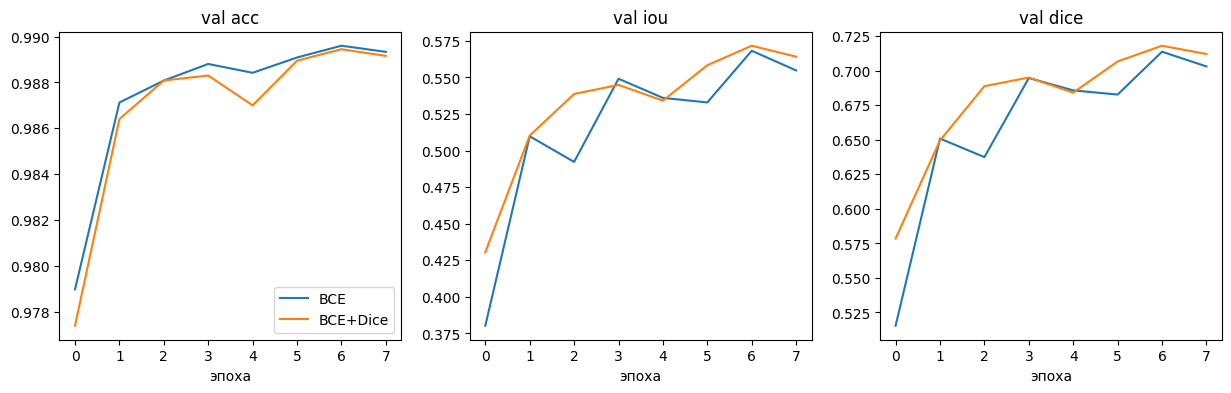

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for h, n in [(h_bce, 'BCE'), (h_dice, 'BCE+Dice')]:
    for a, k in zip(ax, ['acc', 'iou', 'dice']):
        a.plot([e[k] for e in h], label=n); a.set_title('val ' + k); a.set_xlabel('эпоха')
ax[0].legend(); plt.show()

### Смотрим на предсказания

Слева направо: картинка, истинная маска, ответ модели с BCE, ответ модели с BCE+Dice.

In [ ]:
pos = [i for i, m in enumerate(val_ds.masks) if m.mean() > 0.01][:5]

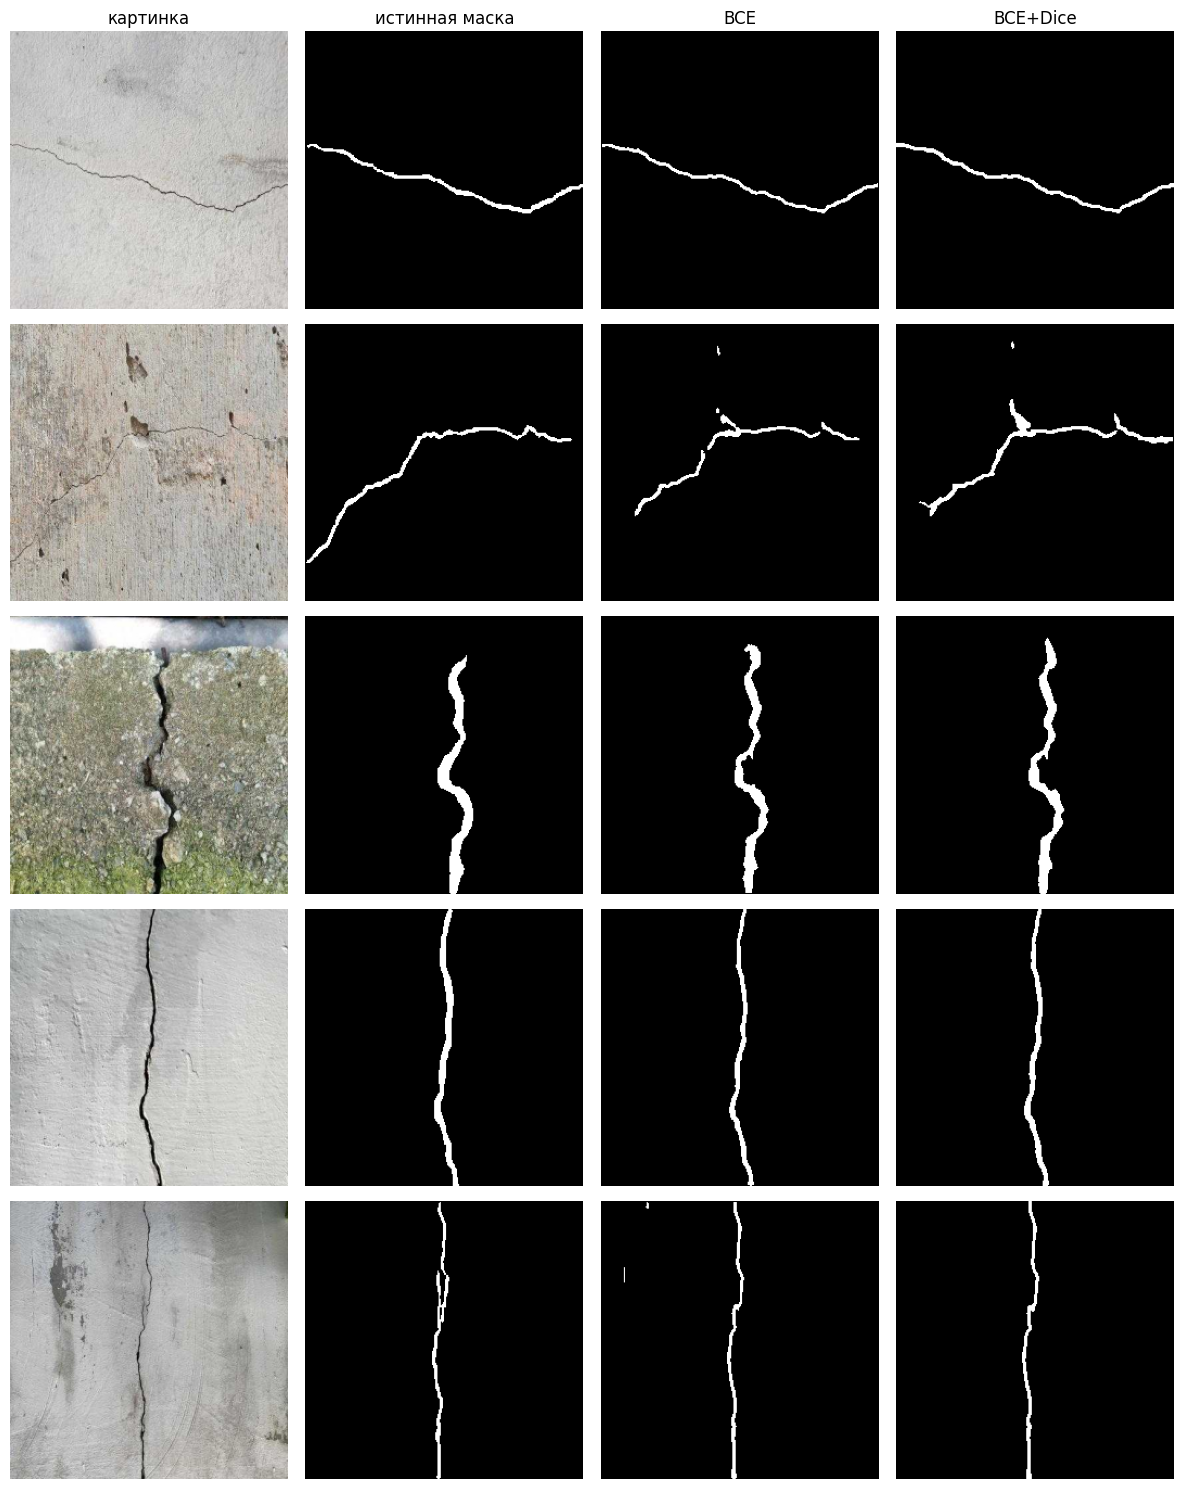

In [ ]:
@torch.no_grad()
def show(models, ds, idxs):
    fig, ax = plt.subplots(len(idxs), 2 + len(models), figsize=(3 * (2 + len(models)), 3 * len(idxs)))
    for r, i in enumerate(idxs):
        x, y = ds[i]
        ax[r, 0].imshow(x.permute(1, 2, 0)); ax[r, 1].imshow(y[0], cmap='gray')
        for c, (name, m) in enumerate(models):
            m.eval(); p = torch.sigmoid(m(x[None].to(device)))[0, 0].cpu()
            ax[r, 2 + c].imshow(p > 0.5, cmap='gray')
            if r == 0: ax[r, 2 + c].set_title(name)
        if r == 0:
            ax[r, 0].set_title('картинка'); ax[r, 1].set_title('истинная маска')
        for a in ax[r]: a.axis('off')
    plt.tight_layout(); plt.show()

show([('BCE', unet_bce), ('BCE+Dice', unet_dice)], val_ds, pos)

доля трещины на val: 10%% / 50%% / 90%% квантили = [     0.0076       0.017      0.0349]


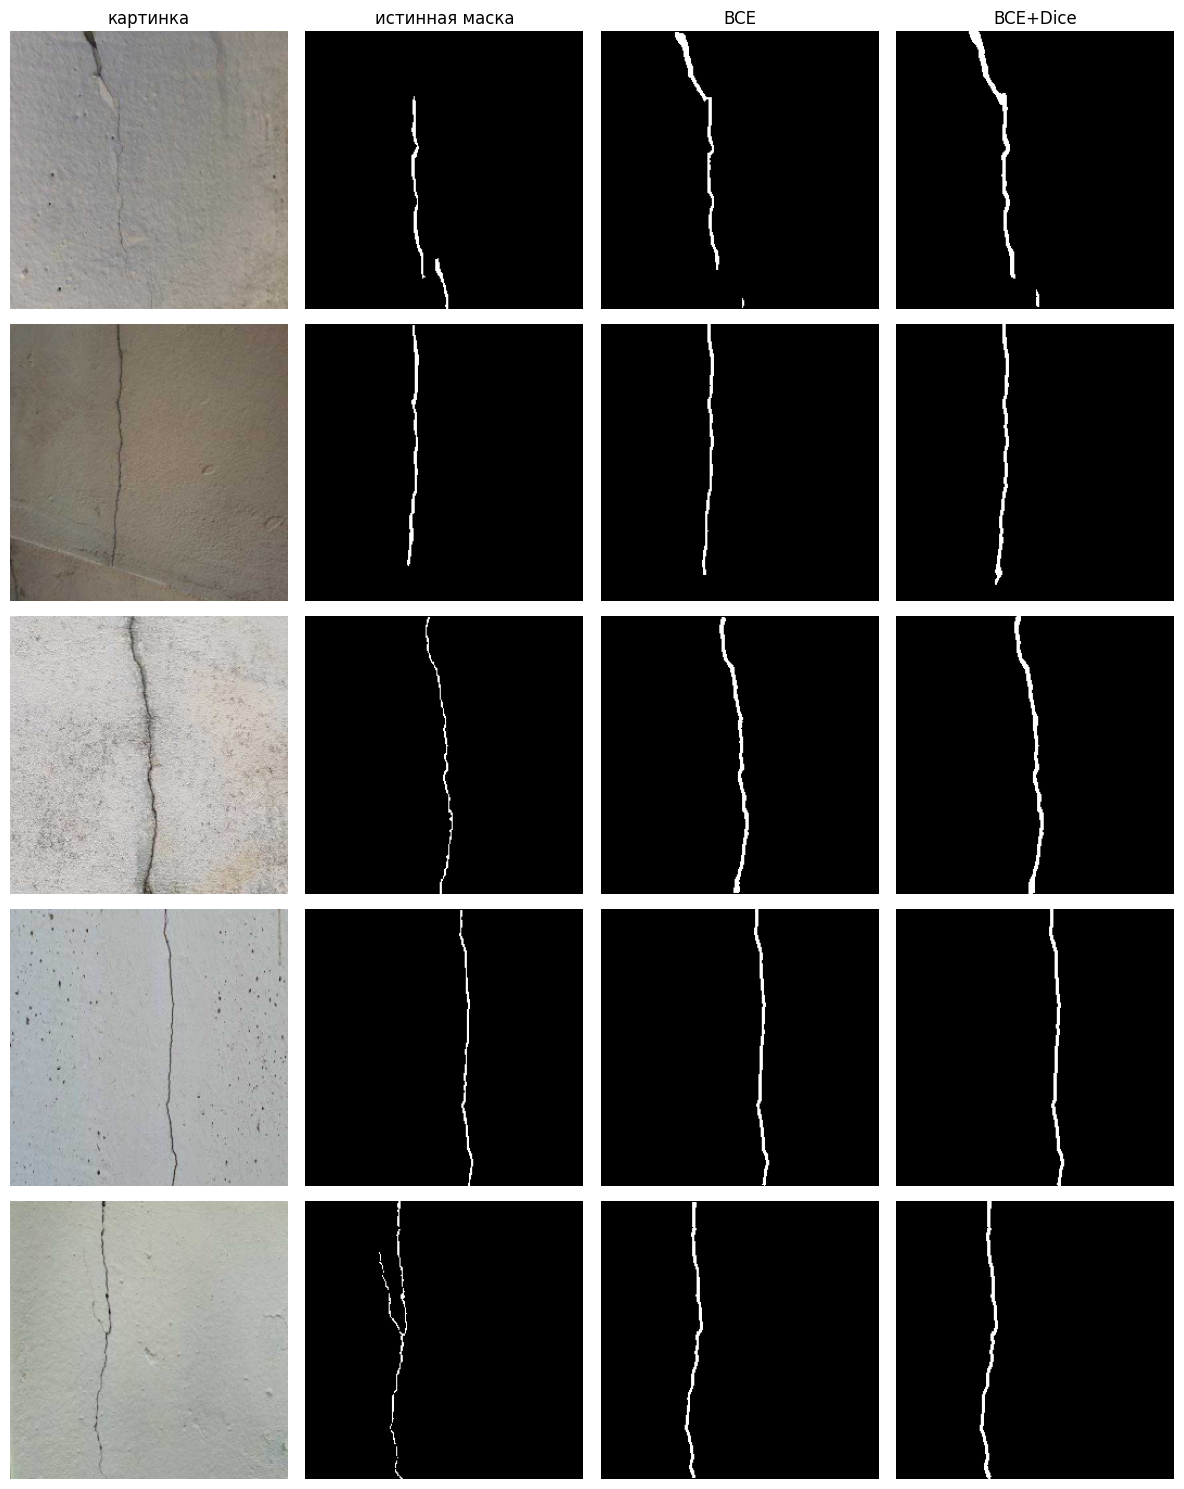

In [ ]:
areas = np.array([m.mean() for m in val_ds.masks])
print('доля трещины на val: 10%% / 50%% / 90%% квантили =', np.quantile(areas[areas > 0], [0.1, 0.5, 0.9]).round(4))

pos_thin = [i for i, a in enumerate(areas) if 0.002 < a < 0.01][:5]
show([('BCE', unet_bce), ('BCE+Dice', unet_dice)], val_ds, pos_thin)

In [ ]:
test_loader = MyDataLoader(test_ds, 32)
for n, m in [('BCE', unet_bce), ('BCE+Dice', unet_dice)]:
    print(f'{n:20s}', {k: round(v, 3) for k, v in evaluate(m, test_loader).items()})

BCE                  {'acc': 0.989, 'iou': 0.537, 'dice': 0.684}
BCE+Dice             {'acc': 0.989, 'iou': 0.545, 'dice': 0.693}


## Приколы

### Feature maps энкодера и декодера

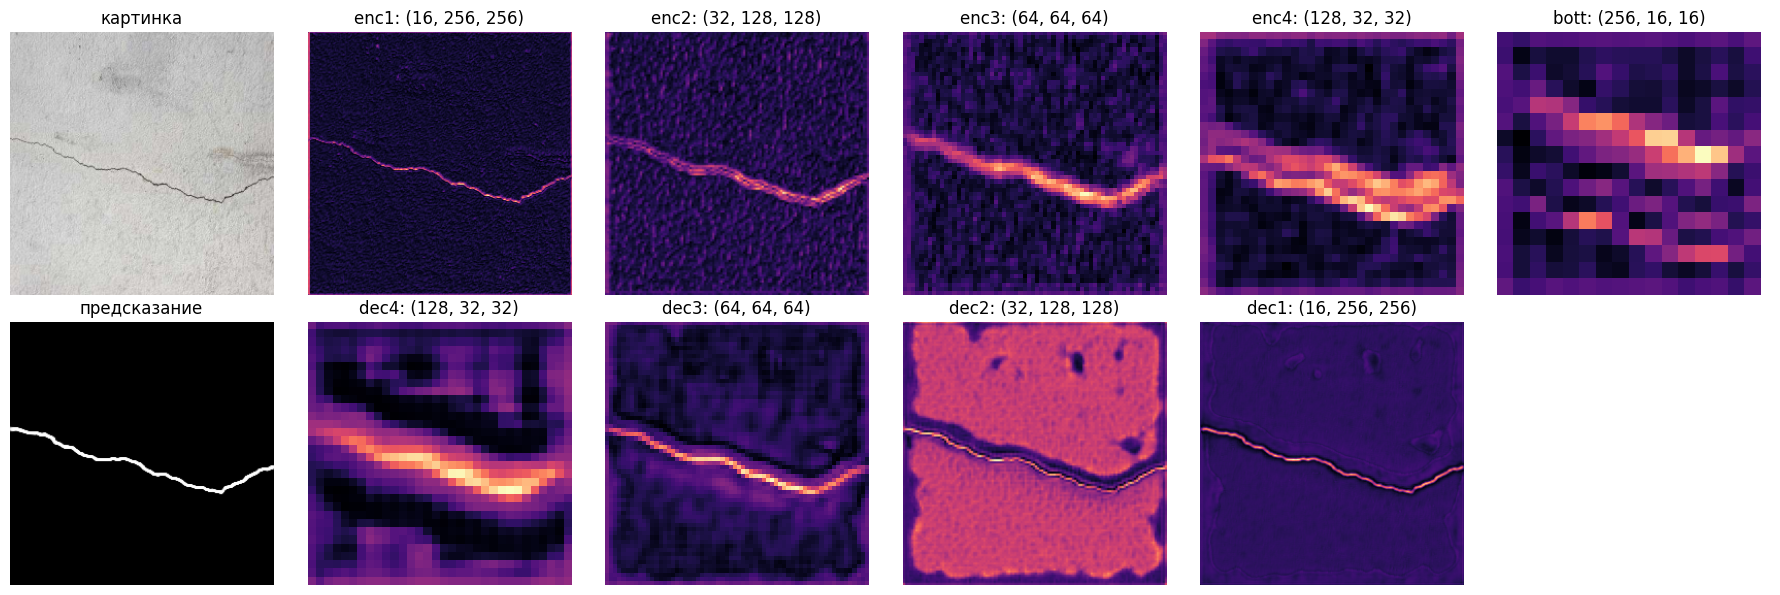

In [ ]:
feats = {}
def save(name):
    def hook(m, i, o): feats[name] = o.detach().cpu()
    return hook

model = unet_dice.eval()
for k, e in enumerate(model.enc): e.register_forward_hook(save(f'enc{k+1}'))
model.bott.register_forward_hook(save('bott'))
for k, d in enumerate(model.dec): d.register_forward_hook(save(f'dec{4-k}'))   # dec[0] — самый глубокий уровень

x, y = val_ds[pos[0]]
with torch.no_grad():
    pred = torch.sigmoid(model(x[None].to(device)))[0, 0].cpu()

names = ['enc1', 'enc2', 'enc3', 'enc4', 'bott', 'dec4', 'dec3', 'dec2', 'dec1']
fig, ax = plt.subplots(2, 6, figsize=(18, 6))
ax[0, 0].imshow(x.permute(1, 2, 0)); ax[0, 0].set_title('картинка')
ax[1, 0].imshow(pred, cmap='gray');  ax[1, 0].set_title('предсказание')
for a, n in zip(list(ax[0, 1:]) + list(ax[1, 1:]), names):
    f = feats[n][0].abs().mean(0)
    a.imshow(f, cmap='magma'); a.set_title(f'{n}: {tuple(feats[n].shape[1:])}')
for a in ax.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

## Карта вероятностей вместо маски

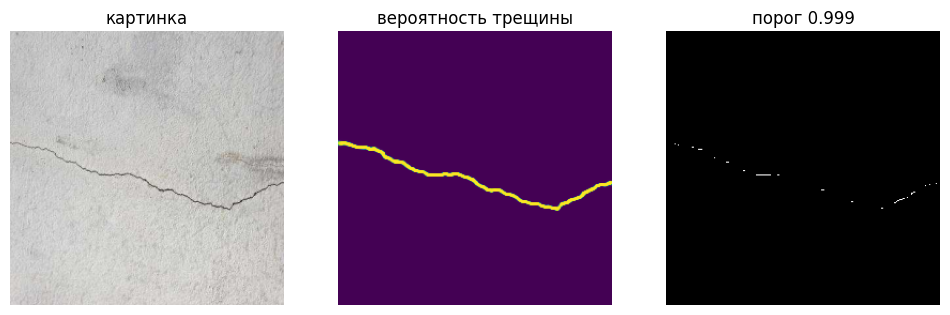

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(x.permute(1, 2, 0)); ax[1].imshow(pred, cmap='viridis', vmin=0, vmax=1)
ax[2].imshow(pred > 0.999, cmap='gray')
ax[0].set_title('картинка'); ax[1].set_title('вероятность трещины'); ax[2].set_title('порог 0.999')
for a in ax: a.axis('off')
plt.show()

### Карты ошибок

нашлось тонких трещин: 4


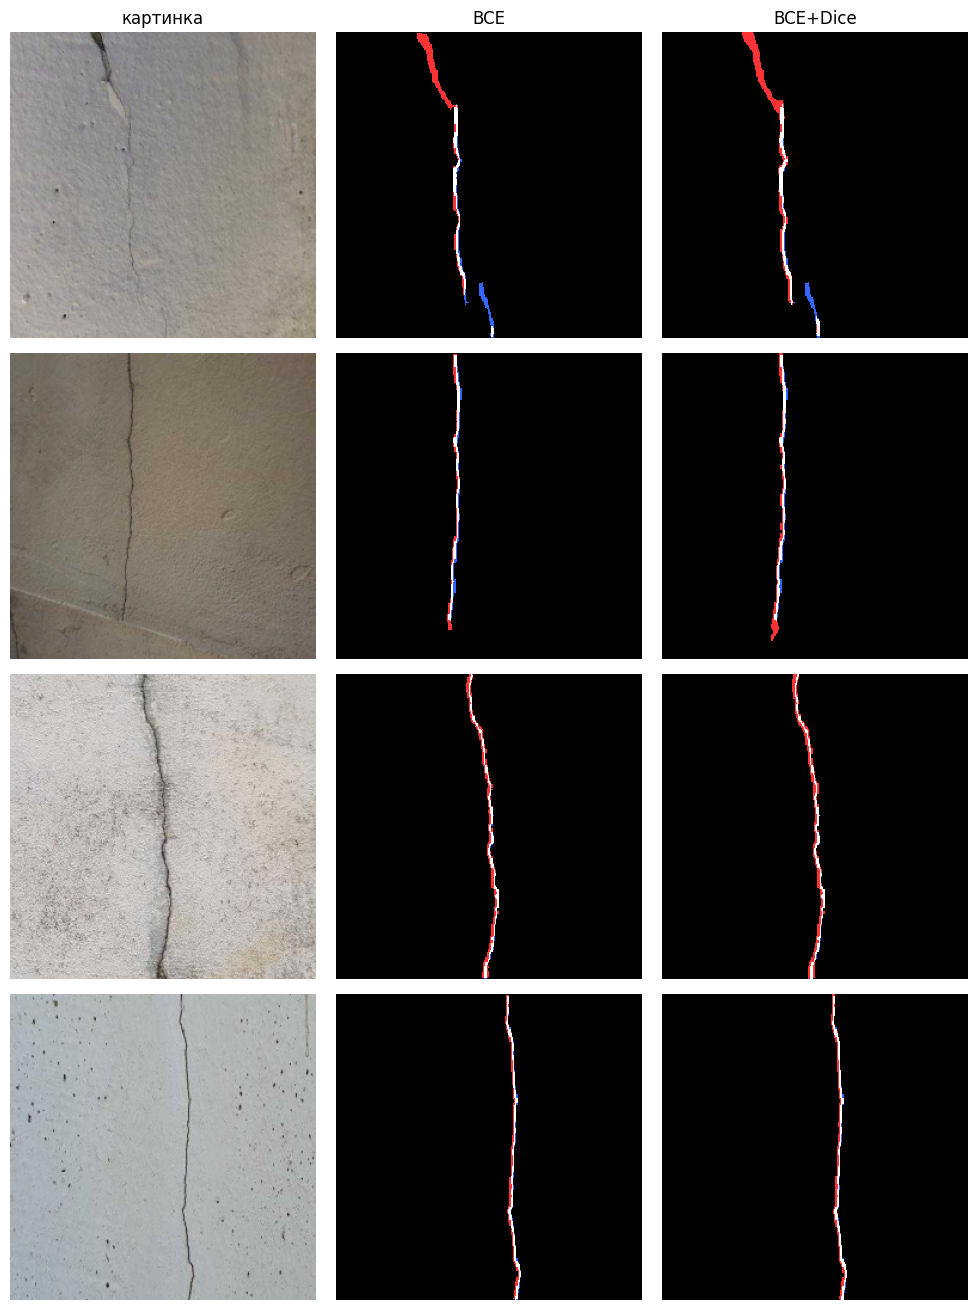

белый — совпало, красный — лишнее (FP), синий — пропущено (FN)


In [ ]:
def error_map(pred_mask, true_mask):
    p, t = pred_mask.bool(), true_mask.bool()
    out = torch.zeros(*p.shape, 3)
    out[p & t]  = torch.tensor([1., 1., 1.])        # TP — белый
    out[p & ~t] = torch.tensor([1., 0.2, 0.2])      # FP — красный (выдумала)
    out[~p & t] = torch.tensor([0.2, 0.4, 1.])      # FN — синий (пропустила)
    return out

areas = np.array([m.mean() for m in val_ds.masks])
thin = [i for i, a in enumerate(areas) if 0.002 < a < 0.01][:4]     # тонкие: маленькая, но не нулевая доля
print('нашлось тонких трещин:', len(thin))

models = [('BCE', unet_bce), ('BCE+Dice', unet_dice)]
fig, ax = plt.subplots(len(thin), 3, figsize=(10, 3.3 * len(thin)))
for r, i in enumerate(thin):
    x, y = val_ds[i]
    ax[r, 0].imshow(x.permute(1, 2, 0))
    for c, (name, m) in enumerate(models, start=1):
        with torch.no_grad():
            p = torch.sigmoid(m.eval()(x[None].to(device)))[0, 0].cpu() > 0.5
        ax[r, c].imshow(error_map(p, y[0]), interpolation='nearest')
        if r == 0: ax[r, c].set_title(name)
    if r == 0: ax[r, 0].set_title('картинка')
    for a in ax[r]: a.axis('off')
plt.tight_layout(); plt.show()
print('белый — совпало, красный — лишнее (FP), синий — пропущено (FN)')

# Блок 2. Детекция животных

## Задание 2.1. Читаем разметку YOLO

Файл разметки: одна строка на объект `class cx cy w h`, все числа нормированы на [0, 1] (центр, ширина и высота рамки). Напишите `load_yolo_labels(path, w, h)`, которая возвращает

* `boxes` — `np.float32` `(N, 4)` в пикселях, формат `[x1, y1, x2, y2]`;
* `cls` — `np.int64` `(N,)`.

Файла может не быть или он может быть пустым, тогда вернуть пустые массивы.

In [ ]:
A = '/content/data/african-wildlife'
NAMES = ['buffalo', 'elephant', 'rhino', 'zebra']

def load_yolo_labels(path, w, h):
    if not os.path.exists(path):
        return np.zeros((0, 4), np.float32), np.zeros((0,), np.int64)
    rows = [l.split() for l in open(path) if l.strip()]
    if not rows:
        return np.zeros((0, 4), np.float32), np.zeros((0,), np.int64)
    a = np.array(rows, dtype=np.float32)
    cx, cy, bw, bh = a[:, 1] * w, a[:, 2] * h, a[:, 3] * w, a[:, 4] * h
    boxes = np.stack([cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2], 1).astype(np.float32)
    return boxes, a[:, 0].astype(np.int64)

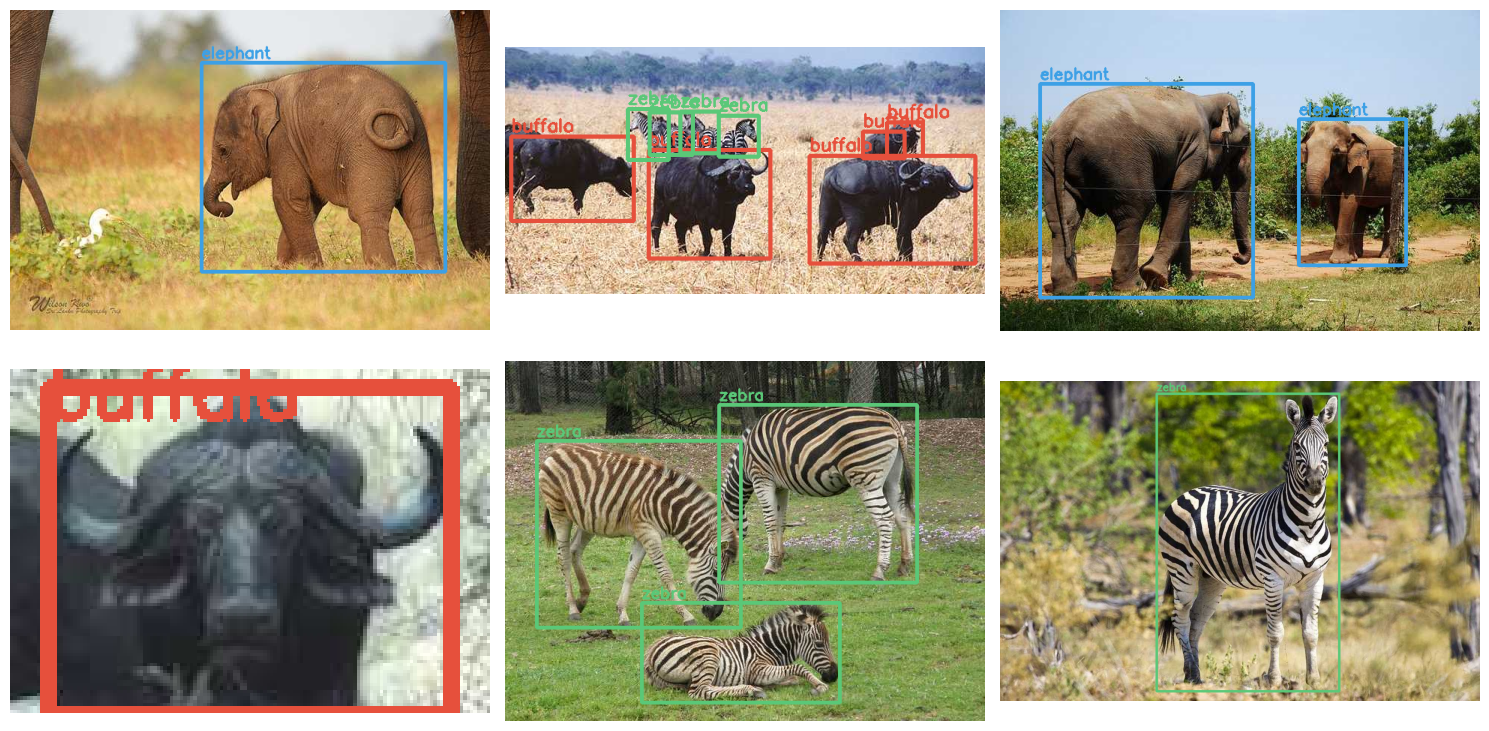

In [ ]:
COLORS = [(230, 80, 60), (60, 160, 230), (240, 190, 40), (90, 200, 120)]

def draw_boxes(img, boxes, cls, scores=None, names=NAMES):
    img = img.copy()
    for i, (b, c) in enumerate(zip(boxes, cls)):
        x1, y1, x2, y2 = map(int, b)
        col = COLORS[c % len(COLORS)]
        cv2.rectangle(img, (x1, y1), (x2, y2), col, 3)
        tag = names[c] + ('' if scores is None else f' {scores[i]:.2f}')
        cv2.putText(img, tag, (x1, max(y1 - 6, 14)), cv2.FONT_HERSHEY_SIMPLEX, 0.7, col, 2)
    return img

files = sorted(glob.glob(f'{A}/images/train/*.jpg'))
random.seed(1); sample = random.sample(files, 6)
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for a, p in zip(ax.ravel(), sample):
    img = cv2.imread(p)[:, :, ::-1]; h, w = img.shape[:2]
    b, c = load_yolo_labels(p.replace('/images/', '/labels/').replace('.jpg', '.txt'), w, h)
    assert b.shape[1:] == (4,) and (b[:, 2] > b[:, 0]).all()
    a.imshow(draw_boxes(img, b, c)); a.axis('off')
plt.tight_layout(); plt.show()

## Задание 2.2. IoU для массивов рамок

Напишите `box_iou_np(a, b)`: `a` имеет форму `(N, 4)`, `b` — `(M, 4)`, формат `[x1, y1, x2, y2]`. Результат — матрица `(N, M)` попарных IoU. Без циклов по парам, через broadcasting (`a[:, None]` и `b[None]`).

In [ ]:
def box_iou_np(a, b):
    a, b = np.asarray(a, np.float32), np.asarray(b, np.float32)
    lt = np.maximum(a[:, None, :2], b[None, :, :2])
    rb = np.minimum(a[:, None, 2:], b[None, :, 2:])
    inter = np.clip(rb - lt, 0, None).prod(2)
    area_a = (a[:, 2:] - a[:, :2]).prod(1)
    area_b = (b[:, 2:] - b[:, :2]).prod(1)
    return inter / (area_a[:, None] + area_b[None] - inter + 1e-9)

In [ ]:
import torchvision
r = np.random.RandomState(0)
xy = r.rand(20, 2) * 100; wh = r.rand(20, 2) * 50 + 5
A_ = np.concatenate([xy, xy + wh], 1).astype(np.float32)
ref = torchvision.ops.box_iou(torch.from_numpy(A_[:8]), torch.from_numpy(A_)).numpy()
assert np.allclose(box_iou_np(A_[:8], A_), ref, atol=1e-5)
assert np.allclose(np.diag(box_iou_np(A_, A_)), 1, atol=1e-5)
print('ok')

ok


## Задание 2.3. Свой NMS

Жадный алгоритм: берём рамку с максимальным score, оставляем её, выбрасываем все остальные с IoU `> thr` относительно неё, повторяем.

`nms_np(boxes, scores, thr)` возвращает **индексы** оставленных рамок в порядке убывания score. Используйте `box_iou_np`.

In [ ]:
def nms_np(boxes, scores, thr=0.45):
    order = np.argsort(-scores)
    keep = []
    while len(order):
        i = order[0]
        keep.append(i)
        if len(order) == 1:
            break
        iou = box_iou_np(boxes[i:i+1], boxes[order[1:]])[0]
        order = order[1:][iou <= thr]
    return np.array(keep, dtype=np.int64)

In [ ]:
r = np.random.RandomState(1)
xy = r.rand(300, 2) * 200; wh = r.rand(300, 2) * 60 + 10
B_ = np.concatenate([xy, xy + wh], 1).astype(np.float32); S_ = r.rand(300).astype(np.float32)
for thr in (0.3, 0.5, 0.7):
    mine = nms_np(B_, S_, thr)
    ref = torchvision.ops.nms(torch.from_numpy(B_), torch.from_numpy(S_), thr).numpy()
    assert list(mine) == list(ref), thr
print('совпало с torchvision.ops.nms')

совпало с torchvision.ops.nms


## Что на самом деле выдаёт сеть

`model.predict()` скрывает всё: и подготовку картинки, и NMS. Достанем «голую» сеть и посмотрим, что она отдаёт. Для `yolo11n` с 4 классами выход имеет форму **`(1, 4 + 4, 8400)`**:

* 8400 = 80² + 40² + 20² — кандидаты на трёх масштабах (картинка 640 → сетки 80, 40, 20);
* 4 числа — рамка `cx, cy, w, h` в пикселях входной картинки;
* 4 числа — оценки классов (отдельного «objectness» нет).

Подготовка входа (letterbox: вписать в квадрат 640×640 с серыми полями) дана.

In [ ]:
from ultralytics import YOLO

net = YOLO('yolo11n.pt').model.to(device).eval()      # официальные веса YOLO11n, COCO, 80 классов

def letterbox(img, size=640):
    h, w = img.shape[:2]; r = min(size / h, size / w)
    nh, nw = round(h * r), round(w * r)
    canvas = np.full((size, size, 3), 114, np.uint8)
    top, left = (size - nh) // 2, (size - nw) // 2
    canvas[top:top + nh, left:left + nw] = cv2.resize(img, (nw, nh))
    return canvas, r, left, top

p = sorted(glob.glob(f'{A}/images/test/*.jpg'))[3]
img = cv2.imread(p)[:, :, ::-1]
canvas, r, left, top = letterbox(img)
x = torch.from_numpy(canvas).permute(2, 0, 1)[None].float().div(255).to(device)
with torch.no_grad():
    out = net(x)
raw = (out[0] if isinstance(out, (list, tuple)) else out).cpu()
print('сырой выход:', tuple(raw.shape))

сырой выход: (1, 84, 8400)


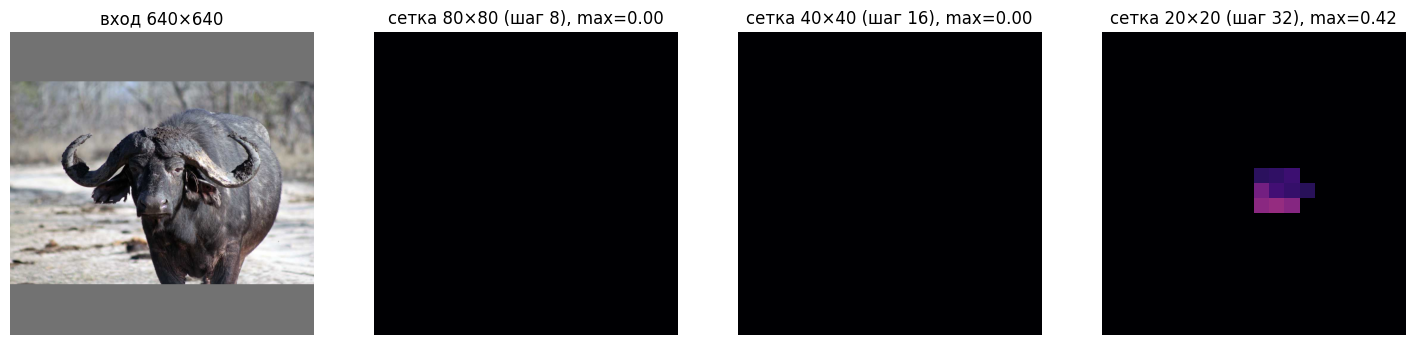

In [ ]:
p = sorted(glob.glob(f'{A}/images/test/*.jpg'))[57]       # вместо [3]; дальше весь код ячейки без изменений

scores = raw[0, 4:].max(0).values.numpy()                 # для каждого из 8400 кандидатов: лучшая оценка по классам
sizes = [80, 40, 20]
parts = np.split(scores, np.cumsum([s * s for s in sizes])[:-1])
maps = [pp.reshape(s, s) for pp, s in zip(parts, sizes)]

fig, ax = plt.subplots(1, 4, figsize=(18, 4.6))
ax[0].imshow(canvas); ax[0].set_title('вход 640×640')
for a, m, s in zip(ax[1:], maps, sizes):
    a.imshow(m, cmap='magma', vmin=0, vmax=1)
    a.set_title(f'сетка {s}×{s} (шаг {640 // s}), max={m.max():.2f}')
for a in ax: a.axis('off')
plt.show()

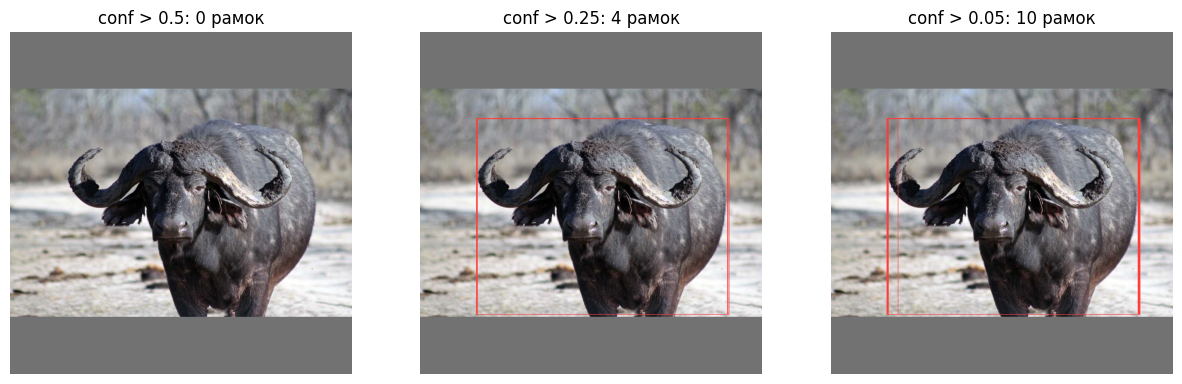

In [ ]:
cls = raw[0, 4:].argmax(0).numpy()

def boxes_before_nms(thr):
    m = scores > thr
    b = raw[0, :4].T.numpy()[m]
    xyxy = np.concatenate([b[:, :2] - b[:, 2:] / 2, b[:, :2] + b[:, 2:] / 2], 1)
    return xyxy, scores[m], cls[m]

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, thr in zip(ax, (0.5, 0.25, 0.05)):
    b, s, c = boxes_before_nms(thr)
    canvas2 = canvas.copy()
    for x1, y1, x2, y2 in b.astype(int):
        cv2.rectangle(canvas2, (x1, y1), (x2, y2), (255, 60, 60), 1)
    a.imshow(canvas2); a.set_title(f'conf > {thr}: {len(b)} рамок'); a.axis('off')
plt.show()

## Задание 2.4. Делаем рамки

Напишите `decode(raw, conf_thr=0.25, iou_thr=0.45)`, где `raw` — тензор `(1, 4+nc, 8400)`:

1. транспонировать в `(8400, 4+nc)`;
2. для каждого кандидата класс = `argmax` оценок, уверенность = максимум;
3. отбросить кандидатов с уверенностью `< conf_thr`;
4. перевести `cx, cy, w, h` в `x1, y1, x2, y2`;
5. **NMS по каждому классу отдельно** (зебра не должна подавлять слона). Приём: сдвиньте рамки класса `c` на `c · 4096` пикселей, тогда рамки разных классов не пересекаются, и вызовите свой `nms_np` один раз;
6. вернуть рамки (без сдвига), уверенности и классы.

Затем вернём рамки в координаты исходной картинки (функция дана).

In [ ]:
def decode(raw, conf_thr=0.25, iou_thr=0.45):
    p = raw[0].T.numpy()                       # (8400, 4+nc)
    box, sc = p[:, :4], p[:, 4:]
    cls = sc.argmax(1); conf = sc.max(1)
    m = conf >= conf_thr
    box, cls, conf = box[m], cls[m], conf[m]
    xyxy = np.concatenate([box[:, :2] - box[:, 2:] / 2, box[:, :2] + box[:, 2:] / 2], 1)
    if len(xyxy) == 0:
        return xyxy, conf, cls
    keep = nms_np(xyxy + cls[:, None] * 4096., conf, iou_thr)
    return xyxy[keep], conf[keep], cls[keep]

def to_original(boxes, r, left, top, w, h):
    b = (boxes - np.array([left, top, left, top])) / r
    return np.clip(b, 0, [w, h, w, h])

после порога и NMS осталось рамок: 1
рамок у ultralytics: 9
для каждой нашей рамки лучший IoU с рамками ultralytics: [       0.01]


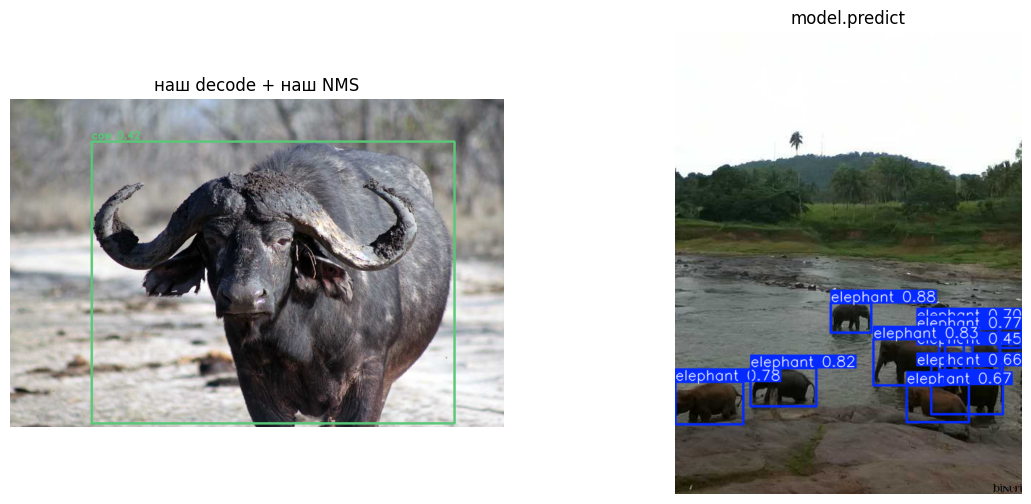

In [ ]:
h, w = img.shape[:2]
b, s, c = decode(raw)
b = to_original(b, r, left, top, w, h)
print(f'после порога и NMS осталось рамок: {len(b)}')
assert len(b) > 0 and b.shape[1] == 4

# сравниваем с «официальным» предсказанием
res = YOLO('yolo11n.pt').predict(p, conf=0.25, iou=0.45, verbose=False, device=0 if device == 'cuda' else 'cpu')[0]
ref_b = res.boxes.xyxy.cpu().numpy()
print('рамок у ultralytics:', len(ref_b))
if len(ref_b) and len(b):
    best_iou = box_iou_np(b, ref_b).max(1)
    print('для каждой нашей рамки лучший IoU с рамками ultralytics:', best_iou.round(2))
COCO = YOLO('yolo11n.pt').names
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].imshow(draw_boxes(img, b, c, s, names=COCO)); ax[0].set_title('наш decode + наш NMS')
ax[1].imshow(res.plot()[:, :, ::-1]); ax[1].set_title('model.predict')
for a in ax: a.axis('off')
plt.show()

## Как запустить обучение yolo на наших данных?


In [ ]:
import os

aw_yaml = '''path: /content/data/african-wildlife
train: images/train
val: images/val
test: images/test
names: {0: buffalo, 1: elephant, 2: rhino, 3: zebra}
'''
open('/content/aw.yaml', 'w').write(aw_yaml)

from ultralytics import YOLO

train_args = dict(data='/content/aw.yaml', epochs=5, imgsz=640, batch=16, workers=2,
                  plots=False, project='/content/runs', exist_ok=True)

def train_both():
    YOLO('yolo26n.pt').train(name='pretrained', **train_args)                   # с весов COCO
    YOLO('yolo26n.yaml').train(name='scratch', pretrained=False, **train_args)  # со случайными весами

train_both()

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/aw.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=pretrained, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, o

KeyboardInterrupt: 

In [ ]:
def average_precision(tp_flags, n_gt):
    """AP по всем точкам кривой precision–recall (как в Pascal VOC 2010+)."""
    if n_gt == 0 or len(tp_flags) == 0:
        return 0.0
    tp = np.cumsum(tp_flags); fp = np.cumsum(1 - np.asarray(tp_flags))
    rec, prec = tp / n_gt, tp / (tp + fp)
    mrec = np.concatenate([[0.], rec, [1.]]); mpre = np.concatenate([[0.], prec, [0.]])
    mpre = np.maximum.accumulate(mpre[::-1])[::-1]            # огибающая: precision не растёт при росте recall
    i = np.where(mrec[1:] != mrec[:-1])[0]
    return float(np.sum((mrec[i + 1] - mrec[i]) * mpre[i + 1]))

@torch.no_grad()
def evaluate_detector(net, files, nc=4, conf_thr=0.01, nms_thr=0.6, iou_match=0.5, size=640, report_conf=0.25):
    dets = [[] for _ in range(nc)]                  # на класс: список (score, 1 если TP, иначе 0)
    n_gt = np.zeros(nc, int)
    for p in files:
        img = cv2.imread(p)[:, :, ::-1]; h, w = img.shape[:2]
        gt_b, gt_c = load_yolo_labels(p.replace('/images/', '/labels/').replace('.jpg', '.txt'), w, h)
        canvas, r, left, top = letterbox(img, size)
        x = torch.from_numpy(canvas).permute(2, 0, 1)[None].float().div(255).to(device)
        out = net(x); raw = (out[0] if isinstance(out, (list, tuple)) else out).cpu()
        b, s, c = decode(raw, conf_thr, nms_thr)
        b = to_original(b, r, left, top, w, h)
        for k in range(nc):
            g = gt_b[gt_c == k]; n_gt[k] += len(g)
            m = c == k; bk, sk = b[m], s[m]
            order = np.argsort(-sk); bk, sk = bk[order], sk[order]       # сначала самые уверенные
            used = np.zeros(len(g), bool)
            for box, score in zip(bk, sk):
                tp = 0
                if len(g):
                    ious = box_iou_np(box[None], g)[0]; j = ious.argmax()
                    if ious[j] >= iou_match and not used[j]:             # настоящую рамку можно «найти» один раз
                        used[j] = True; tp = 1
                dets[k].append((float(score), tp))
    rows = []
    for k in range(nc):
        d = sorted(dets[k], key=lambda t: -t[0])
        flags = [t[1] for t in d]
        sel = [t for t in d if t[0] >= report_conf]                       # точка работы: порог уверенности
        tp, n = sum(t[1] for t in sel), len(sel)
        rows.append(dict(класс=NAMES[k], объектов=int(n_gt[k]), AP50=average_precision(flags, n_gt[k]),
                         precision=tp / n if n else 0., recall=float(tp / n_gt[k]) if n_gt[k] else 0.))
    return rows

In [ ]:
import pandas as pd

w = '/content/runs/pretrained/weights/best.pt'          # веса, обученные в фоне
net = YOLO(w).model.to(device).eval()
test_files = sorted(glob.glob(f'{A}/images/test/*.jpg'))

rows = evaluate_detector(net, test_files)
df = pd.DataFrame(rows).round(3); display(df)
print('наш mAP@0.5: %.3f' % df['AP50'].mean())

m = YOLO(w).val(data='/content/aw.yaml', split='test', imgsz=640, conf=0.001, iou=0.6,
                verbose=False, plots=False)
print('Ultralytics mAP@0.5: %.3f' % m.box.map50, dict(zip(NAMES, m.box.ap50.round(3))))

,класс,объектов,AP50,precision,recall
0,buffalo,66,0.959,0.913,0.955
1,elephant,99,0.962,0.922,0.949
2,rhino,75,0.995,0.960,0.960
3,zebra,135,0.942,0.857,0.933


наш mAP@0.5: 0.964
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1377.3±791.8 MB/s, size: 53.5 KB)
val: Scanning /content/data/african-wildlife/labels/test... 227 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 227/227 2.1Kit/s 0.1s
val: New cache created: /content/data/african-wildlife/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 5.6it/s 2.7s
                   all        227        375      0.951      0.912      0.964      0.784
Speed: 0.7ms preprocess, 5.8ms inference, 0.0ms loss, 1.3ms postprocess per image
Ultralytics mAP@0.5: 0.964 {'buffalo': np.float64(0.944), 'elephant': np.float64(0.976), 'rhino': np.float64(0.99), 'zebra': np.float64(0.946)}


## Приколы

### Feature Map

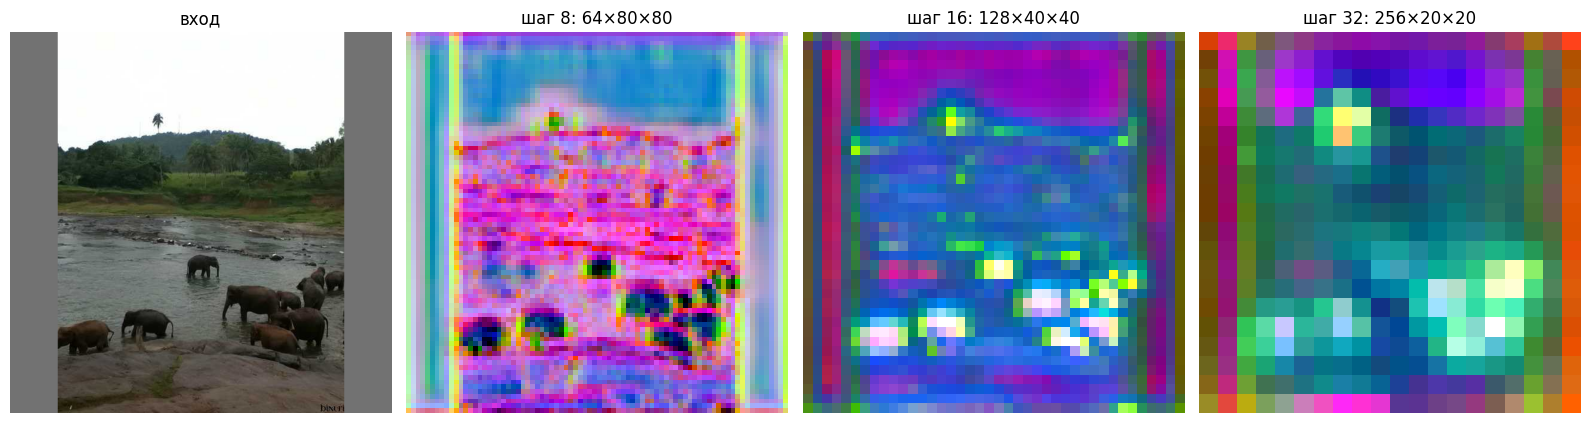

In [ ]:
COCO = YOLO('yolo11n.pt').names                       # классы COCO для готовой модели

def run_raw(net, img, size=640):
    canvas, r, left, top = letterbox(img, size)
    x = torch.from_numpy(canvas).permute(2, 0, 1)[None].float().div(255).to(device)
    with torch.no_grad(): out = net(x)
    return (out[0] if isinstance(out, (list, tuple)) else out).cpu(), (r, left, top)

def pca_rgb(f):
    """f: (C, H, W) -> картинка (H, W, 3): первые 3 главные компоненты как цвета."""
    C, H, W = f.shape
    X = f.reshape(C, -1).T.float(); X = X - X.mean(0)
    _, _, Vt = torch.linalg.svd(X, full_matrices=False)
    P = (X @ Vt[:3].T).T.reshape(3, H, W)
    lo = torch.quantile(P.reshape(3, -1), 0.02, dim=1)[:, None, None]
    hi = torch.quantile(P.reshape(3, -1), 0.98, dim=1)[:, None, None]
    return ((P - lo) / (hi - lo + 1e-8)).clamp(0, 1).permute(1, 2, 0).numpy()

def show_feature_pca(net, img):
    feats = []
    h = net.model[-1].register_forward_pre_hook(lambda m, args: feats.extend(t.detach().cpu() for t in args[0]))
    canvas, *_ = letterbox(img)
    run_raw(net, img); h.remove()                       # хук нужно снять
    fig, ax = plt.subplots(1, 4, figsize=(16, 4.4))
    ax[0].imshow(canvas); ax[0].set_title('вход')
    for a, f, s in zip(ax[1:], feats, (8, 16, 32)):
        a.imshow(pca_rgb(f[0])); a.set_title(f'шаг {s}: {f.shape[1]}×{f.shape[2]}×{f.shape[3]}')
    for a in ax: a.axis('off')
    plt.tight_layout(); plt.show()

img = cv2.imread(sorted(glob.glob(f'{A}/images/test/*.jpg'))[57])[:, :, ::-1]
show_feature_pca(YOLO('yolo11n.pt').model.to(device).eval(), img)

###  Метрики на картинке

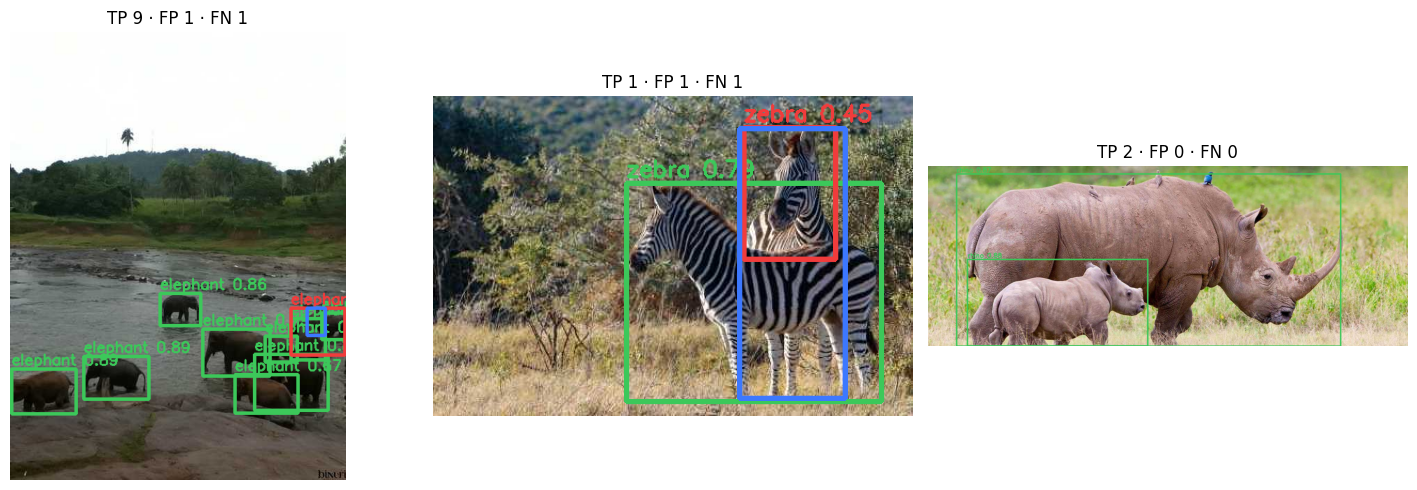

зелёный — найдено (TP), красный — лишнее (FP), синий — пропущено (FN)


In [ ]:
def match_and_draw(img, boxes, scores, cls, gt_b, gt_c, names, iou_match=0.5):
    img = img.copy(); used = np.zeros(len(gt_b), bool); n_tp = n_fp = 0
    for i in np.argsort(-scores):                       # от самых уверенных
        ok = False
        same = np.where((gt_c == cls[i]) & ~used)[0]
        if len(same):
            ious = box_iou_np(boxes[i:i+1], gt_b[same])[0]; j = ious.argmax()
            if ious[j] >= iou_match: used[same[j]] = True; ok = True
        col = (60, 200, 90) if ok else (240, 60, 60)    # TP зелёный, FP красный
        n_tp += ok; n_fp += not ok
        x1, y1, x2, y2 = boxes[i].astype(int)
        cv2.rectangle(img, (x1, y1), (x2, y2), col, 3)
        cv2.putText(img, f'{names[cls[i]]} {scores[i]:.2f}', (x1, max(y1 - 6, 14)), cv2.FONT_HERSHEY_SIMPLEX, 0.7, col, 2)
    for b in gt_b[~used].astype(int):                   # FN синий: пропущенные настоящие рамки
        cv2.rectangle(img, tuple(b[:2]), tuple(b[2:]), (60, 120, 255), 3)
    return img, n_tp, n_fp, int((~used).sum())

def show_matches(net, files, names=NAMES, conf_thr=0.25, nms_thr=0.5):
    fig, ax = plt.subplots(1, len(files), figsize=(5 * len(files), 5))
    for a, p in zip(np.atleast_1d(ax), files):
        img = cv2.imread(p)[:, :, ::-1]; h, w = img.shape[:2]
        gt_b, gt_c = load_yolo_labels(p.replace('/images/', '/labels/').replace('.jpg', '.txt'), w, h)
        raw, (r, left, top) = run_raw(net, img)
        b, s, c = decode(raw, conf_thr, nms_thr); b = to_original(b, r, left, top, w, h)
        out, tp, fp, fn = match_and_draw(img, b, s, c, gt_b, gt_c, names)
        a.imshow(out); a.set_title(f'TP {tp} · FP {fp} · FN {fn}'); a.axis('off')
    plt.tight_layout(); plt.show()
    print('зелёный — найдено (TP), красный — лишнее (FP), синий — пропущено (FN)')

files = sorted(glob.glob(f'{A}/images/test/*.jpg'))
trained = YOLO('/content/runs/pretrained/weights/best.pt').model.to(device).eval()
show_matches(trained, [files[57], files[190], files[114]])

### Пороги conf и NMS

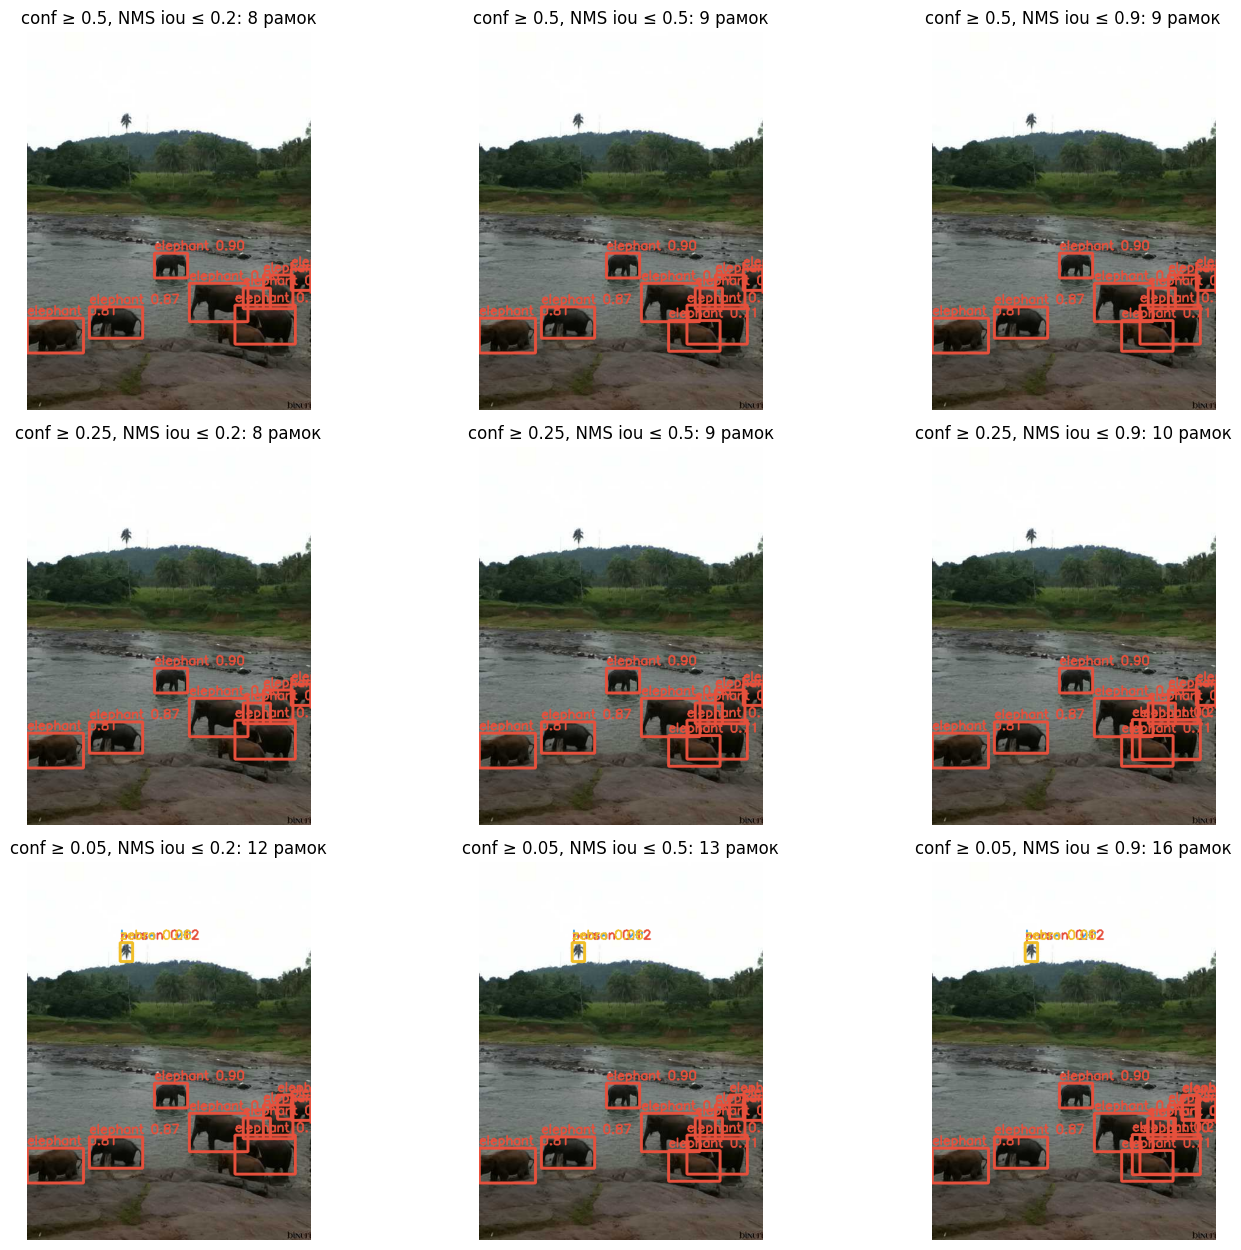

In [ ]:
def threshold_grid(net, img, names, confs=(0.5, 0.25, 0.05), ious=(0.2, 0.5, 0.9)):
    raw, (r, left, top) = run_raw(net, img); h, w = img.shape[:2]
    fig, ax = plt.subplots(len(confs), len(ious), figsize=(5 * len(ious), 4.2 * len(confs)))
    for i, cf in enumerate(confs):
        for j, nm in enumerate(ious):
            b, s, c = decode(raw, cf, nm); b = to_original(b, r, left, top, w, h)
            ax[i, j].imshow(draw_boxes(img, b, c, s, names=names))
            ax[i, j].set_title(f'conf ≥ {cf}, NMS iou ≤ {nm}: {len(b)} рамок'); ax[i, j].axis('off')
    plt.tight_layout(); plt.show()

threshold_grid(YOLO('yolo11n.pt').model.to(device).eval(), img, COCO)